### Load models to pass from B_magn to H(x)

In [45]:
import torch
import torch.nn as nn
import torch.optim as optim
#from tqdm.notebook import trange, tqdm
from tqdm.auto import trange, tqdm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import scipy.io as sio
import pandas as pd
import joblib

# for inference
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Dataset

In [46]:
# Carica il file di testo (rileva automaticamente i nomi delle colonne dalla prima riga)
# 1. Load dataset
column_names = ['B_magn_T', 'TPU_L_mm', 't_index', 't_val_s', 'x_coord_m', 'H_val_Am', 'B_val_T']

df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+', header=None, names=column_names, index_col=False)

# dataset shape
print("Shape del dataset originale:", df.shape)

# remove data with B = 0
df_no_zero = df[df['B_magn_T'] != 0]
print("Shape del dataset senza zeri:", df_no_zero.shape)

# only time instant 1
df_no_zero_t_1 = df_no_zero[df_no_zero['t_index'] == 1]
print("Shape del dataset filtrato - time instant 1:", df_no_zero_t_1.shape)
# print(df_no_zero_t_1.iloc[0:100])


C:\Users\andre\AppData\Local\Temp\ipykernel_46452\679864684.py:5: DtypeWarning: Columns (0: B_magn_T, 1: TPU_L_mm, 2: t_index, 3: t_val_s, 4: x_coord_m, 5: H_val_Am, 6: B_val_T) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+', header=None, names=column_names, index_col=False)


Shape del dataset originale: (872641, 7)
Shape del dataset senza zeri: (872641, 7)
Shape del dataset filtrato - time instant 1: (7325, 7)


Model architecture

In [47]:
class NN_get_Bx(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=64, n_hidden2=32):
        super(NN_get_Bx, self).__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)
        self.fc2 = nn.Linear(n_hidden1, n_hidden2)
        self.fc3 = nn.Linear(n_hidden2, n_output)
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    

# initialize the NN
class NN_get_Hx(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=16,n_hidden2=16): #relu 16
        super(NN_get_Hx, self).__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)  # 3 input features,
        self.fc2 = nn.Linear(n_hidden1, n_hidden2) #
        self.fc3 = nn.Linear(n_hidden2, n_output)  # 1 output
        self.ReLU  = nn.ReLU ()
    def forward(self, x):
        x = self.ReLU (self.fc1(x))
        x = self.ReLU (self.fc2(x))
        x = self.fc3(x)
        return x


Load model and scaler

In [48]:
# B_magn to B(x)

# Carica lo scaler
scaler_X_B_magn_to_Bx = joblib.load('scaler_X_B_magn_to_Bx.pkl')

# Ricrea la stessa architettura e carica i pesi
model_Bx = NN_get_Bx(n_input=3, n_output=1)
model_Bx.load_state_dict(torch.load('model_B_magn_To_Bx.pth', weights_only=True))
model_Bx.eval()

# H(x) from B(x)

# Carica lo scaler
scaler_X_Bx_to_Hx = joblib.load('scaler_X_Bx_to_Hx.pkl')
scaler_Y_Bx_to_Hx = joblib.load('scaler_y_Bx_to_Hx.pkl')
# Ricrea la stessa architettura e carica i pesi
model_Hx = NN_get_Hx(n_input=3, n_output=1)
model_Hx.load_state_dict(torch.load('model_Bx_To_Hx.pth', weights_only=True))
model_Hx.eval()

NN_get_Hx(
  (fc1): Linear(in_features=3, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=1, bias=True)
  (ReLU): ReLU()
)

Concatenation

In [49]:
def predict_H(B_magn_T, TPU_L_mm, x_coord_m):
    # Stage 1: [B_magn_T, TPU_L_mm, x_coord_m] → B(x)
    X1 = np.array([[B_magn_T, TPU_L_mm, x_coord_m]])
    X1_scaled = scaler_X_B_magn_to_Bx.transform(X1)
    with torch.no_grad():
        B_pred = model_Bx(torch.tensor(X1_scaled, dtype=torch.float32)).item()
    # B_val_T non era scalato → usalo direttamente

    # Stage 2: [TPU_L_mm, x_coord_m, B(x)] → H(x)
    X2 = np.array([[TPU_L_mm, x_coord_m, B_pred]])
    X2_scaled = scaler_X_Bx_to_Hx.transform(X2)
    with torch.no_grad():
        H_scaled = model_Hx(torch.tensor(X2_scaled, dtype=torch.float32)).numpy()
    H_pred = scaler_Y_Bx_to_Hx.inverse_transform(H_scaled.reshape(-1, 1)).ravel()[0]

    return B_pred, H_pred

In [50]:
# ── Test su un punto singolo ──────────────────────────────────────
B_pred, H_pred = predict_H(B_magn_T=0.5, TPU_L_mm=30, x_coord_m=0.015)
print(f"B(x) predetto: {B_pred:.4f} T")
print(f"H(x) predetto: {H_pred:.2f} A/m")

B(x) predetto: 0.1961 T
H(x) predetto: 22190.31 A/m


Trovati 19 punti reali


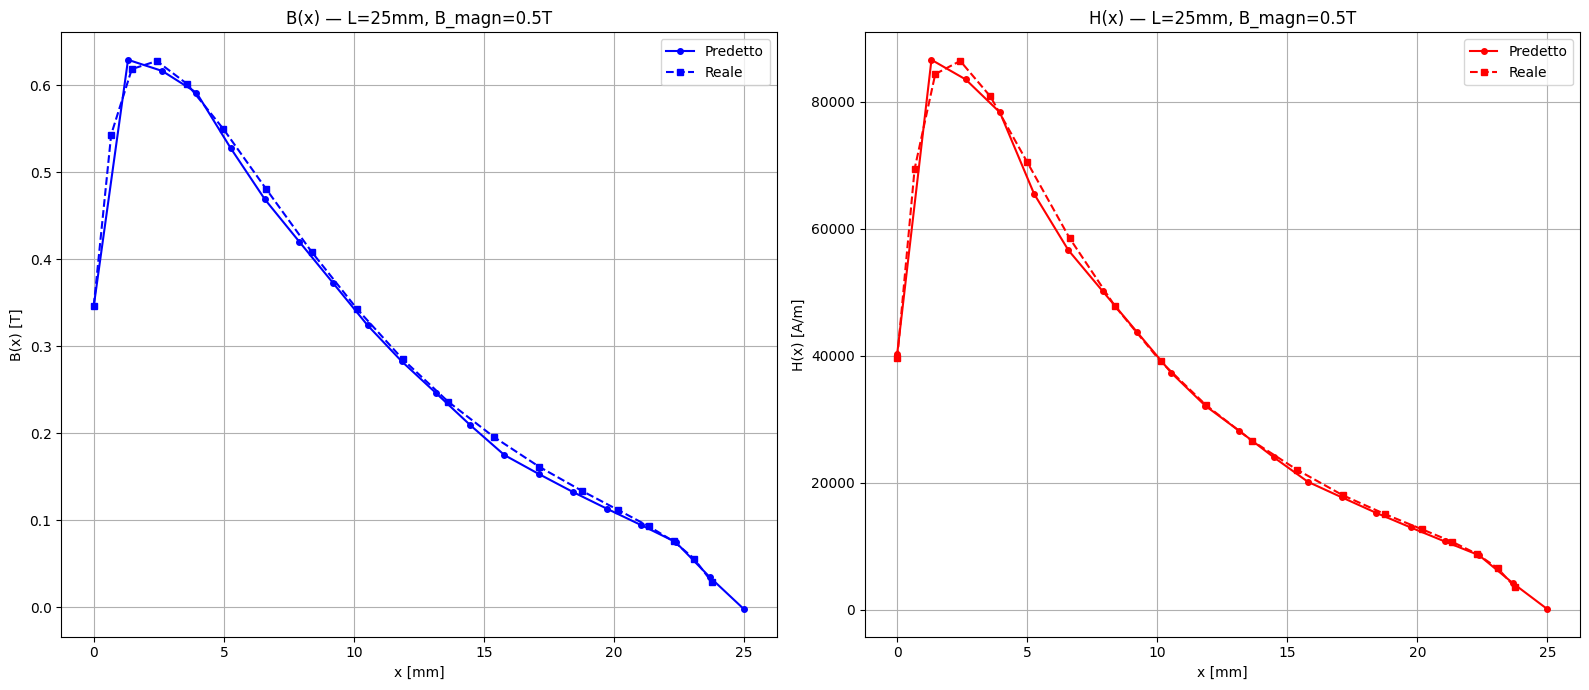

RMSE B(x): 0.0138 T
RMSE H(x): 1686.9 A/m


In [51]:
# ── Test su una curva intera ──────────────────────────────────────
tpu   = 25    # mm
b_mag = 0.5   # T
x_points = np.linspace(0, tpu/1000, 20)

# ── Estrai curva reale dal dataset ────────────────────────────────
blocco_reale = (df_no_zero_t_1[
                    (df_no_zero_t_1['TPU_L_mm'].round(1)  == round(tpu, 1)) &
                    (df_no_zero_t_1['B_magn_T'].round(1)  == round(b_mag, 1))]
                .sort_values('x_coord_m')
                .reset_index(drop=True))

if blocco_reale.empty:
    print(f"  Nessun dato reale trovato per TPU_L={tpu}mm, B_magn={b_mag}T")
    print(f"   TPU_L disponibili: {sorted(df_no_zero_t_1['TPU_L_mm'].unique())}")
    print(f"   B_magn disponibili: {sorted(df_no_zero_t_1['B_magn_T'].unique())}")
else:
    x_real  = blocco_reale['x_coord_m'].values
    Bx_real = blocco_reale['B_val_T'].values
    Hx_real = blocco_reale['H_val_Am'].values
    print(f"Trovati {len(blocco_reale)} punti reali")

# ── Predizioni ────────────────────────────────────────────────────
B_curve, H_curve = [], []
for x in x_points:
    b, h = predict_H(b_mag, tpu, x)
    B_curve.append(float(b))   # ← forza a float Python
    H_curve.append(float(h))   # ← forza a float Python

# ── Plot ──────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].plot(x_points * 1000, B_curve,  'b-o',  ms=4, label='Predetto')
axes[0].plot(x_real   * 1000, Bx_real,  'b--s', ms=4, label='Reale')
axes[0].set(xlabel='x [mm]', ylabel='B(x) [T]',
            title=f'B(x) — L={tpu}mm, B_magn={b_mag}T')
axes[0].legend(); axes[0].grid(True)

axes[1].plot(x_points * 1000, H_curve,  'r-o',  ms=4, label='Predetto')
axes[1].plot(x_real   * 1000, Hx_real,  'r--s', ms=4, label='Reale')
axes[1].set(xlabel='x [mm]', ylabel='H(x) [A/m]',
            title=f'H(x) — L={tpu}mm, B_magn={b_mag}T')
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

#print(type(x_real), x_real.dtype)
#print(type(x_points), x_points.dtype)
#print(type(B_curve[0]), type(H_curve[0]))

# ── Metriche ──────────────────────────────────────────────────────
if not blocco_reale.empty:
    x_real_f   = np.array(x_real,   dtype=np.float64)
    x_points_f = np.array(x_points, dtype=np.float64)
    B_curve_f  = np.array(B_curve,  dtype=np.float64)
    H_curve_f  = np.array(H_curve,  dtype=np.float64)
 # Interpola la predetta sui punti x reali per confronto corretto
    B_pred_interp = np.interp(x_real_f, x_points_f, B_curve_f)
    H_pred_interp = np.interp(x_real_f, x_points_f, H_curve_f)
   

    rmse_B = np.sqrt(np.mean((B_pred_interp - Bx_real)**2))
    rmse_H = np.sqrt(np.mean((H_pred_interp - Hx_real)**2))
    print(f"RMSE B(x): {rmse_B:.4f} T")
    print(f"RMSE H(x): {rmse_H:.1f} A/m")

Comparison with real curve

In [52]:
# ═══════════════════════════════════════════════════════════════════
# VENTAGLIO DI CURVE H(x) per ogni TPU_L
# Per ogni valore di TPU_L disponibile → un subplot
# Dentro ogni subplot: una curva per ogni B_magn disponibile
# ═══════════════════════════════════════════════════════════════════

# ── PARAMETRI ────────────────────────────────────────────────────
SHOW_TRUE   = True    # True = sovrappone anche la curva reale
SCALE_LOG   = False   # True = asse y in scala logaritmica
# ─────────────────────────────────────────────────────────────────

# Valori unici di TPU_L e B_magn nel dataset
tpu_vals  = sorted(df_no_zero_t_1['TPU_L_mm'].unique())
b_vals    = sorted(df_no_zero_t_1['B_magn_T'].unique())


n_tpu  = len(tpu_vals)
n_cols = 3
n_rows = int(np.ceil(n_tpu / n_cols))

print(f"Valori unici di TPU_L: {tpu_vals}")
print(f"Valori unici di B_magn: {b_vals}")
print(f"Organizzazione subplot: {n_rows} righe x {n_cols} colonne")

Valori unici di TPU_L: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
Valori unici di B_magn: [0.189473684210526, 0.252631578947368, 0.315789473684211, 0.378947368421053, 0.442105263157895, 0.505263157894737, 0.568421052631579, 0.631578947368421, 0.694736842105263, 0.757894736842105, 0.821052631578947, 0.88421052631579, 0.947368421052632, 1.01052631578947, 1.07368421052632, 1.13684210526316, 1.2]
Organizzazione subplot: 7 righe x 3 colonne


In [53]:
# ── RMSE per ogni curva ad ogni TPU_L — modello cascata ──────────
print(f"\nValutazione dettagliata per tutti i TPU_L")
print(f"\n{'TPU_L':>8} | {'B_magn [T]':>10} | {'RMSE [A/m]':>12} | {'MAE [A/m]':>12} | {'ErrRel Max':>12} | {'ErrRel Med':>12}")
print("-" * 80)

tpu_vals = sorted(df_no_zero_t_1['TPU_L_mm'].unique())
rmse_all = []

for tpu in tpu_vals:
    df_tpu   = df_no_zero_t_1[df_no_zero_t_1['TPU_L_mm'] == tpu]
    b_in_tpu = sorted(df_tpu['B_magn_T'].unique())

    for b in b_in_tpu:
        blocco = (df_tpu[df_tpu['B_magn_T'] == b]
                  .sort_values('x_coord_m')
                  .reset_index(drop=True))

        H_true   = blocco['H_val_Am'].values
        x_coords = blocco['x_coord_m'].values
        x_mm     = x_coords * 1000

        # ── Stage 1: [B_magn_T, TPU_L_mm, x_coord_m] → B(x) ────
        X1 = np.column_stack([
            np.full(len(blocco), b),      # B_magn_T
            np.full(len(blocco), tpu),    # TPU_L_mm
            x_coords,                     # x_coord_m
        ])
        X1_scaled = scaler_X_B_magn_to_Bx.transform(X1)
        with torch.no_grad():
            B_pred = model_Bx(torch.FloatTensor(X1_scaled)).numpy().ravel()
        # B_val_T non era scalato → usalo direttamente

        # ── Stage 2: [TPU_L_mm, x_coord_m, B(x)] → H(x) ────────
        X2 = np.column_stack([
            np.full(len(blocco), tpu),    # TPU_L_mm
            x_coords,                     # x_coord_m
            B_pred,                       # B(x) predetto dallo stage 1
        ])
        X2_scaled = scaler_X_Bx_to_Hx.transform(X2)
        with torch.no_grad():
            H_pred_s = model_Hx(torch.FloatTensor(X2_scaled)).numpy().ravel()
        H_pred = scaler_Y_Bx_to_Hx.inverse_transform(
                     H_pred_s.reshape(-1, 1)).ravel()

        # ── Metriche ─────────────────────────────────────────────
        err_abs  = np.abs(H_pred - H_true)
        err_rel  = err_abs / (np.abs(H_true) + 1e-9)
        rmse     = np.sqrt(np.mean((H_pred - H_true) ** 2))
        mae      = np.mean(err_abs)
        rel_max  = err_rel.max()
        rel_mean = err_rel.mean()

        rmse_all.append({
            'TPU_L_mm'   : tpu,
            'B_magn_T'   : b,
            'RMSE'       : rmse,
            'MAE'        : mae,
            'RelErr_max' : rel_max,
            'RelErr_mean': rel_mean,
            'x_mm'       : x_mm,
            'H_true'     : H_true,
            'H_pred'     : H_pred,
            'B_pred'     : B_pred,   # utile per debug
            'err_abs'    : err_abs,
        })

        print(f"{tpu:>7.0f}mm | {b:>10.3f} | {rmse:>12.1f} | "
              f"{mae:>12.1f} | {rel_max*100:>11.2f}% | {rel_mean*100:>11.2f}%")

# ── Riepilogo ────────────────────────────────────────────────────
df_rmse_all = pd.DataFrame([{k: v for k, v in r.items()
                              if k not in ('x_mm','H_true','H_pred','B_pred','err_abs')}
                             for r in rmse_all])

df_rmse_all['RelErr_max %']  = (df_rmse_all['RelErr_max']  * 100).round(2)
df_rmse_all['RelErr_mean %'] = (df_rmse_all['RelErr_mean'] * 100).round(2)

print(f"\n{'='*80}")
print(f"Totale curve valutate: {len(rmse_all)}")
print(f"RMSE medio globale:    {df_rmse_all['RMSE'].mean():.1f} A/m")
print(f"RMSE mediano:          {df_rmse_all['RMSE'].median():.1f} A/m")

print(f"\n── Top 5 peggiori per RMSE ──")
print(df_rmse_all.nlargest(5, 'RMSE')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n── Top 10 peggiori per errore relativo massimo ──")
print(df_rmse_all.nlargest(10, 'RelErr_max')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))


Valutazione dettagliata per tutti i TPU_L

   TPU_L | B_magn [T] |   RMSE [A/m] |    MAE [A/m] |   ErrRel Max |   ErrRel Med
--------------------------------------------------------------------------------
     20mm |      0.253 |       1233.6 |        963.8 |       14.74% |        5.23%
     20mm |      0.316 |       1127.7 |        874.6 |       12.80% |        3.89%
     20mm |      0.379 |        988.4 |        735.2 |       21.29% |        3.78%
     20mm |      0.442 |       1129.9 |        924.3 |       30.36% |        4.47%
     20mm |      0.505 |       1254.9 |       1030.9 |       37.68% |        4.88%
     20mm |      0.568 |       1721.3 |       1268.2 |       43.72% |        5.27%
     20mm |      0.632 |       2242.2 |       1655.8 |       43.95% |        5.50%
     20mm |      0.695 |       2429.1 |       1787.9 |       46.20% |        5.32%
     20mm |      0.758 |       1865.3 |       1461.0 |       48.61% |        4.60%
     20mm |      0.821 |       1864.0 |       

In [54]:
# ── Riepilogo ────────────────────────────────────────────────────
df_rmse_all = pd.DataFrame([{k: v for k, v in r.items()
                              if k not in ('x_mm','H_true','H_pred','err_abs')}
                             for r in rmse_all])

df_rmse_all['RelErr_max %']  = (df_rmse_all['RelErr_max']  * 100).round(2)
df_rmse_all['RelErr_mean %'] = (df_rmse_all['RelErr_mean'] * 100).round(2)

print(f"\n{'='*80}")
print(f"Totale curve valutate: {len(rmse_all)}")
print(f"RMSE medio globale:    {df_rmse_all['RMSE'].mean():.1f} A/m")
print(f"RMSE mediano:          {df_rmse_all['RMSE'].median():.1f} A/m")

print(f"\n── Top 3 peggiori per RMSE ──")
print(df_rmse_all.nlargest(3, 'RMSE')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n── Top 3 peggiori per errore relativo massimo ──")
print(df_rmse_all.nlargest(3, 'RelErr_max')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n - Numero di curve con errore relativo massimo > 10%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 10].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 20%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 20].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 30%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 30].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 40%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 40].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 50%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 50].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 60%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 60].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 70%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 70].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 80%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 80].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 90%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 90].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 100%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 100].shape[0]}")


Totale curve valutate: 356
RMSE medio globale:    1066.9 A/m
RMSE mediano:          989.9 A/m

── Top 3 peggiori per RMSE ──
 TPU_L_mm  B_magn_T        RMSE         MAE  RelErr_max %  RelErr_mean %
       20  1.200000 4532.815487 3080.775859         93.05           7.33
       21  1.200000 3379.457054 2316.875506         78.35           6.12
       20  1.136842 3035.715594 1929.910072         83.00           6.02

── Top 3 peggiori per errore relativo massimo ──
 TPU_L_mm  B_magn_T        RMSE         MAE  RelErr_max %  RelErr_mean %
       20  1.200000 4532.815487 3080.775859         93.05           7.33
       20  1.136842 3035.715594 1929.910072         83.00           6.02
       21  1.200000 3379.457054 2316.875506         78.35           6.12

 - Numero di curve con errore relativo massimo > 10%: 346

 - Numero di curve con errore relativo massimo > 20%: 289

 - Numero di curve con errore relativo massimo > 30%: 186

 - Numero di curve con errore relativo massimo > 40%: 126

 - 

### Test with data created from scratch form COMSOL

In [80]:
# Carica il file di testo (rileva automaticamente i nomi delle colonne dalla prima riga)
# 1. Load dataset
column_names = ['B_magn_T', 'TPU_L_mm', 't_index', 't_val_s', 'x_coord_m', 'H_val_Am', 'B_val_T']

# df_validation = pd.read_csv('Dataset_BH_validation_test.txt', sep=r'\s+', names=column_names, index_col=False)
df_validation = pd.read_csv('Dataset_BH_validation_test.txt', sep='\t',)
# dataset shape
print("Shape del dataset originale:", df_validation.shape)

# remove data with B = 0
df_validation_no_zero = df_validation[df_validation['B_magn_T'] != 0]
print("Shape del dataset senza zeri:", df_validation_no_zero.shape)

# only time instant 1
df_validation_no_zero_t_1 = df_validation_no_zero[df_validation_no_zero['t_index'] == 1]
print("Shape del dataset filtrato - time instant 1:", df_validation_no_zero_t_1.shape)


Shape del dataset originale: (123725, 7)
Shape del dataset senza zeri: (106050, 7)
Shape del dataset filtrato - time instant 1: (1050, 7)


In [75]:
tpu_vals  = sorted(df_validation_no_zero_t_1['TPU_L_mm'].unique())
b_vals    = sorted(df_validation_no_zero_t_1['B_magn_T'].unique())
print(f"Valori unici di TPU_L: {tpu_vals}")
print(f"Valori unici di B_magn: {b_vals}")

Valori unici di TPU_L: [np.float64(21.3), np.float64(26.6), np.float64(31.9), np.float64(37.2), np.float64(42.5)]
Valori unici di B_magn: [np.float64(0.191666666666667), np.float64(0.383333333333333), np.float64(0.575), np.float64(0.766666666666667), np.float64(0.958333333333333), np.float64(1.15)]


Trovati 46 punti reali


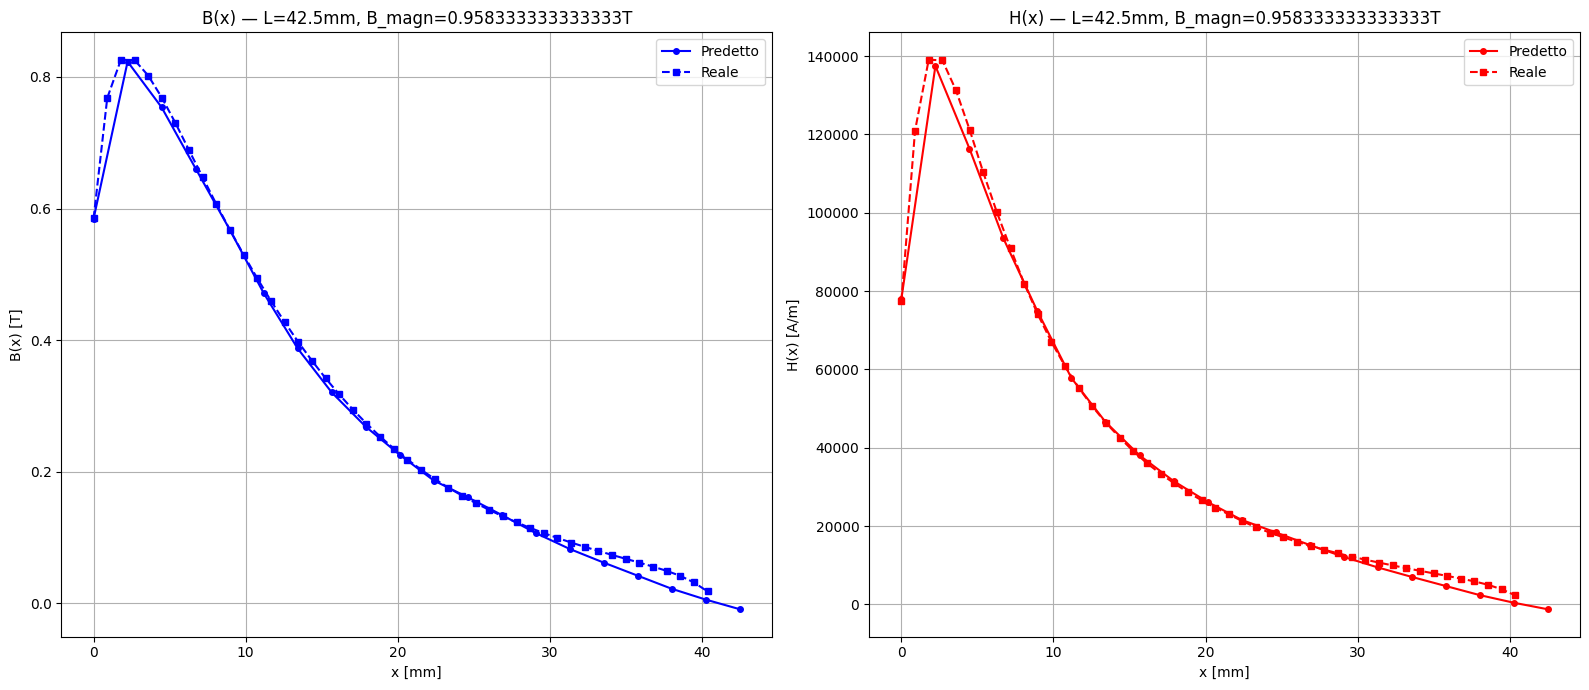

RMSE B(x): 0.0186 T
RMSE H(x): 3985.3 A/m


In [85]:
# ── Test su una curva intera ──────────────────────────────────────
tpu   = tpu_vals[4]    # mm - SELZIONA IL TPU_L CHE VUOI TESTARE
b_mag = b_vals[4]   # T - SELEZIONA IL B_magn CHE VUOI TESTARE

##################################################################à

x_points = np.linspace(0, tpu/1000, 20)

# ── Estrai curva reale dal dataset ────────────────────────────────
blocco_reale = (df_validation_no_zero_t_1[
                    (df_validation_no_zero_t_1['TPU_L_mm'].round(1)  == round(tpu, 1)) &
                    (df_validation_no_zero_t_1['B_magn_T'].round(1)  == round(b_mag, 1))]
                .sort_values('x_coord_m')
                .reset_index(drop=True))

if blocco_reale.empty:
    print(f"  Nessun dato reale trovato per TPU_L={tpu}mm, B_magn={b_mag}T")
    print(f"   TPU_L disponibili: {sorted(df_validation_no_zero_t_1['TPU_L_mm'].unique())}")
    print(f"   B_magn disponibili: {sorted(df_validation_no_zero_t_1['B_magn_T'].unique())}")
else:
    x_real  = blocco_reale['x_coord_m'].values
    Bx_real = blocco_reale['B_val_T'].values
    Hx_real = blocco_reale['H_val_Am'].values
    print(f"Trovati {len(blocco_reale)} punti reali")

# ── Predizioni ────────────────────────────────────────────────────
B_curve, H_curve = [], []
for x in x_points:
    b, h = predict_H(b_mag, tpu, x)
    B_curve.append(float(b))   # ← forza a float Python
    H_curve.append(float(h))   # ← forza a float Python

# ── Plot ──────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].plot(x_points * 1000, B_curve,  'b-o',  ms=4, label='Predetto')
axes[0].plot(x_real   * 1000, Bx_real,  'b--s', ms=4, label='Reale')
axes[0].set(xlabel='x [mm]', ylabel='B(x) [T]',
            title=f'B(x) — L={tpu}mm, B_magn={b_mag}T')
axes[0].legend(); axes[0].grid(True)

axes[1].plot(x_points * 1000, H_curve,  'r-o',  ms=4, label='Predetto')
axes[1].plot(x_real   * 1000, Hx_real,  'r--s', ms=4, label='Reale')
axes[1].set(xlabel='x [mm]', ylabel='H(x) [A/m]',
            title=f'H(x) — L={tpu}mm, B_magn={b_mag}T')
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

#print(type(x_real), x_real.dtype)
#print(type(x_points), x_points.dtype)
#print(type(B_curve[0]), type(H_curve[0]))

# ── Metriche ──────────────────────────────────────────────────────
if not blocco_reale.empty:
    x_real_f   = np.array(x_real,   dtype=np.float64)
    x_points_f = np.array(x_points, dtype=np.float64)
    B_curve_f  = np.array(B_curve,  dtype=np.float64)
    H_curve_f  = np.array(H_curve,  dtype=np.float64)
 # Interpola la predetta sui punti x reali per confronto corretto
    B_pred_interp = np.interp(x_real_f, x_points_f, B_curve_f)
    H_pred_interp = np.interp(x_real_f, x_points_f, H_curve_f)
   

    rmse_B = np.sqrt(np.mean((B_pred_interp - Bx_real)**2))
    rmse_H = np.sqrt(np.mean((H_pred_interp - Hx_real)**2))
    print(f"RMSE B(x): {rmse_B:.4f} T")
    print(f"RMSE H(x): {rmse_H:.1f} A/m")

In [77]:
# Assessment of test validation
# ── RMSE per ogni curva ad ogni TPU_L — modello cascata ──────────
print(f"\nValutazione dettagliata per tutti i TPU_L")
print(f"\n{'TPU_L':>8} | {'B_magn [T]':>10} | {'RMSE [A/m]':>12} | {'MAE [A/m]':>12} | {'ErrRel Max':>12} | {'ErrRel Med':>12}")
print("-" * 80)

tpu_vals = sorted(df_validation_no_zero_t_1['TPU_L_mm'].unique())
rmse_all = []

for tpu in tpu_vals:
    df_tpu   = df_validation_no_zero_t_1[df_validation_no_zero_t_1['TPU_L_mm'] == tpu]
    b_in_tpu = sorted(df_tpu['B_magn_T'].unique())

    for b in b_in_tpu:
        blocco = (df_tpu[df_tpu['B_magn_T'] == b]
                  .sort_values('x_coord_m')
                  .reset_index(drop=True))

        H_true   = blocco['H_val_Am'].values
        x_coords = blocco['x_coord_m'].values
        x_mm     = x_coords * 1000

        # ── Stage 1: [B_magn_T, TPU_L_mm, x_coord_m] → B(x) ────
        X1 = np.column_stack([
            np.full(len(blocco), b),      # B_magn_T
            np.full(len(blocco), tpu),    # TPU_L_mm
            x_coords,                     # x_coord_m
        ])
        X1_scaled = scaler_X_B_magn_to_Bx.transform(X1)
        with torch.no_grad():
            B_pred = model_Bx(torch.FloatTensor(X1_scaled)).numpy().ravel()
        # B_val_T non era scalato → usalo direttamente

        # ── Stage 2: [TPU_L_mm, x_coord_m, B(x)] → H(x) ────────
        X2 = np.column_stack([
            np.full(len(blocco), tpu),    # TPU_L_mm
            x_coords,                     # x_coord_m
            B_pred,                       # B(x) predetto dallo stage 1
        ])
        X2_scaled = scaler_X_Bx_to_Hx.transform(X2)
        with torch.no_grad():
            H_pred_s = model_Hx(torch.FloatTensor(X2_scaled)).numpy().ravel()
        H_pred = scaler_Y_Bx_to_Hx.inverse_transform(
                     H_pred_s.reshape(-1, 1)).ravel()

        # ── Metriche ─────────────────────────────────────────────
        err_abs  = np.abs(H_pred - H_true)
        err_rel  = err_abs / (np.abs(H_true) + 1e-9)
        rmse     = np.sqrt(np.mean((H_pred - H_true) ** 2))
        mae      = np.mean(err_abs)
        rel_max  = err_rel.max()
        rel_mean = err_rel.mean()

        rmse_all.append({
            'TPU_L_mm'   : tpu,
            'B_magn_T'   : b,
            'RMSE'       : rmse,
            'MAE'        : mae,
            'RelErr_max' : rel_max,
            'RelErr_mean': rel_mean,
            'x_mm'       : x_mm,
            'H_true'     : H_true,
            'H_pred'     : H_pred,
            'B_pred'     : B_pred,   # utile per debug
            'err_abs'    : err_abs,
        })

        print(f"{tpu:>7.0f}mm | {b:>10.3f} | {rmse:>12.1f} | "
              f"{mae:>12.1f} | {rel_max*100:>11.2f}% | {rel_mean*100:>11.2f}%")

# ── Riepilogo ────────────────────────────────────────────────────
df_rmse_all_test_validation = pd.DataFrame([{k: v for k, v in r.items()
                              if k not in ('x_mm','H_true','H_pred','B_pred','err_abs')}
                             for r in rmse_all])

df_rmse_all_test_validation['RelErr_max %']  = (df_rmse_all_test_validation['RelErr_max']  * 100).round(2)
df_rmse_all_test_validation['RelErr_mean %'] = (df_rmse_all_test_validation['RelErr_mean'] * 100).round(2)

print(f"\n{'='*80}")
print(f"Totale curve valutate: {len(rmse_all)}")
print(f"RMSE medio globale:    {df_rmse_all_test_validation['RMSE'].mean():.1f} A/m")
print(f"RMSE mediano:          {df_rmse_all_test_validation['RMSE'].median():.1f} A/m")

print(f"\n── Top 5 peggiori per RMSE ──")
print(df_rmse_all_test_validation.nlargest(5, 'RMSE')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n── Top 10 peggiori per errore relativo massimo ──")
print(df_rmse_all_test_validation.nlargest(10, 'RelErr_max')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))


Valutazione dettagliata per tutti i TPU_L

   TPU_L | B_magn [T] |   RMSE [A/m] |    MAE [A/m] |   ErrRel Max |   ErrRel Med
--------------------------------------------------------------------------------
     21mm |      0.192 |       1584.5 |       1201.8 |       25.19% |        7.92%
     21mm |      0.383 |       1341.0 |        832.3 |        8.83% |        2.79%
     21mm |      0.575 |       1477.1 |        960.1 |       38.81% |        3.18%
     21mm |      0.767 |       1953.8 |       1508.5 |       47.37% |        4.25%
     21mm |      0.958 |       1938.6 |       1362.4 |       51.00% |        3.80%
     21mm |      1.150 |       2552.9 |       1747.4 |       61.29% |        4.05%
     27mm |      0.192 |        528.7 |        385.1 |       30.05% |        3.82%
     27mm |      0.383 |       1103.5 |        687.4 |       24.03% |        4.45%
     27mm |      0.575 |       1849.1 |        984.8 |       22.26% |        2.97%
     27mm |      0.767 |       1620.0 |       

In [78]:
# ── Riepilogo ────────────────────────────────────────────────────
df_rmse_all_test_validation = pd.DataFrame([{k: v for k, v in r.items()
                              if k not in ('x_mm','H_true','H_pred','err_abs')}
                             for r in rmse_all])

df_rmse_all_test_validation['RelErr_max %']  = (df_rmse_all_test_validation['RelErr_max']  * 100).round(2)
df_rmse_all_test_validation['RelErr_mean %'] = (df_rmse_all_test_validation['RelErr_mean'] * 100).round(2)

print(f"\n{'='*80}")
print(f"Totale curve valutate: {len(rmse_all)}")
print(f"RMSE medio globale:    {df_rmse_all_test_validation['RMSE'].mean():.1f} A/m")
print(f"RMSE mediano:          {df_rmse_all_test_validation['RMSE'].median():.1f} A/m")

print(f"\n── Top 3 peggiori per RMSE ──")
print(df_rmse_all_test_validation.nlargest(3, 'RMSE')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n── Top 3 peggiori per errore relativo massimo ──")
print(df_rmse_all_test_validation   .nlargest(3, 'RelErr_max')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n - Numero di curve con errore relativo massimo > 10%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 10].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 20%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 20].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 30%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 30].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 40%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 40].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 50%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 50].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 60%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 60].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 70%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 70].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 80%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 80].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 90%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 90].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 100%: {df_rmse_all_test_validation[df_rmse_all_test_validation['RelErr_max %'] > 100].shape[0]}")


Totale curve valutate: 30
RMSE medio globale:    1350.2 A/m
RMSE mediano:          1160.5 A/m

── Top 3 peggiori per RMSE ──
 TPU_L_mm  B_magn_T        RMSE         MAE  RelErr_max %  RelErr_mean %
     21.3  1.150000 2552.942756 1747.360935         61.29           4.05
     26.6  1.150000 2477.491360 1352.601070         32.08           2.67
     26.6  0.958333 2354.412225 1265.908901         19.14           2.39

── Top 3 peggiori per errore relativo massimo ──
 TPU_L_mm  B_magn_T        RMSE         MAE  RelErr_max %  RelErr_mean %
     42.5  0.191667  953.937137  766.504752        197.30          23.61
     42.5  0.575000 1071.655712  898.998976         94.42          13.53
     42.5  0.958333 1937.227137 1372.277948         83.60          11.49

 - Numero di curve con errore relativo massimo > 10%: 28

 - Numero di curve con errore relativo massimo > 20%: 26

 - Numero di curve con errore relativo massimo > 30%: 21

 - Numero di curve con errore relativo massimo > 40%: 14

 - Nume